# Algebra / Dolly：SFT 前后 loss 变化的预实验

**Run：** `math-algebra-numbertheory-dolly-lengthonly-qwen25-1p5b-seed42`  
**原始结果时间（UTC）：** 2026-10-22T09:33:05.382369+00:00  
**模型：** `Qwen/Qwen2.5-1.5B-Instruct`；主报告 checkpoint：step 32。

A2=Algebra、C=Dolly general_qa，各 512 条。两项指标并列考察，不设主次：loss 下降量 ROC-AUC **0.6162**（95% CI 0.5810–0.6498）；相对下降比例 ROC-AUC **0.8563**（95% CI 0.8324–0.8795）。
复用已完成的 A1-SFT 和两个模型的逐样本评分；指标、对照和局限按原预实验的结构展示。

已保存执行输出，直接打开即可查看表格和图。重跑只读取同目录的 `snapshot/`，
不需要 GPU、checkpoint 或原始数据挂载，也不会重新训练模型。
本次长度控制仅用 A2 与 Dolly 重新分桶和匹配，更新日期记录在 manifest 中；目录时间保持不变。

## 1. 问题与评价约定

只在 A1 上做 SFT；A2 是未参与这次 SFT 的 Algebra 样本，C 是 Dolly 通用问答。
两个模型使用完全相同的 token IDs 和回答 mask，只计算回答正文的平均 token NLL（nats/token）。
A2 为正类，所有排序方向预先固定；A1 只用于训练，不参与 A2/C 分类评价。

下降量和相对下降比例并列考察，不设主次。

- loss 下降量：`delta_loss = L_ref - L_sft`。
- 相对下降比例：`relative_gain = (L_ref - L_sft) / max(L_ref, 1e-6)`。
- 基线：`-L_ref`、`-L_sft`，即 loss 低的样本优先；反向基线在附录单列。
- 95% 区间来自 2,000 次按 domain 分层、按问题组重采样的 bootstrap。
  本 notebook 重算 AUC 和 top-k 点估计并与快照核对，区间来自保存的统计结果。

这是**同域识别**预实验，不直接检验被选数据用于后续训练时的实际收益。

In [1]:
import hashlib
import json
import math
import os
import tempfile
from pathlib import Path
if 'MPLCONFIGDIR' not in os.environ:
    scratch = Path('/dev/shm/data-picking-runtime') if Path('/dev/shm').is_dir() else Path(tempfile.gettempdir())/'data-picking-runtime'
    os.environ['MPLCONFIGDIR'] = str(scratch/'matplotlib')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score, roc_curve
%matplotlib inline
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_colwidth',100)

In [2]:
DIRECTORY = '2026-10-22_093305Z_math-algebra-numbertheory-dolly-lengthonly-qwen25-1p5b-seed42'

HERE = next((p for p in [Path.cwd(),Path.cwd()/'experiments-analysis'/DIRECTORY]
             if (p/'snapshot').is_dir() and (p/'manifest.json').is_file()),None)
if HERE is None: raise FileNotFoundError('请使用当前实验目录或仓库根目录作为工作目录。')
SNAPSHOT = HERE/'snapshot'
manifest = json.loads((HERE/'manifest.json').read_text())
for name,info in manifest['files'].items():
    content = (SNAPSHOT/name).read_bytes()
    assert len(content)==info['bytes'] and hashlib.sha256(content).hexdigest()==info['sha256'],name
def load_json(name): return json.loads((SNAPSHOT/name).read_text())
metrics = load_json('metrics.json')
effective = load_json('effective_config.json')
completed = load_json('training_complete.json')
extension = load_json('extension_config.json')
data_summary = load_json('data_summary.json')
duplicates = load_json('duplicate_report.json')
evaluation = pd.read_parquet(SNAPSHOT/'per_example.parquet')
training = pd.read_json(SNAPSHOT/'train.jsonl',lines=True)
matched_ids = load_json('length_matched_ids.json')
assert evaluation['id'].is_unique
assert evaluation.groupby('domain').size().to_dict()=={'A':512,'C':512}
assert set(evaluation['split'])=={'A2','C'}
assert len(set(matched_ids))==len(matched_ids) and set(matched_ids)<=set(evaluation['id'])
matched = evaluation.set_index('id').loc[matched_ids].reset_index()
assert completed['global_step']==metrics['checkpoint_step'] and metrics['primary_checkpoint']
c_manifest = pd.read_json(SNAPSHOT/'c_manifest.jsonl',lines=True)
selected_c = c_manifest.loc[c_manifest['selected']].set_index('id').sort_index()
assert len(selected_c)==512 and selected_c['sequence_tokens'].le(2048).all()
assert selected_c['response_tokens'].gt(0).all() and selected_c['exclusion_reason'].isna().all()
pd.testing.assert_series_equal(selected_c['tokenization_hash'],
    evaluation.loc[evaluation['domain']=='C'].set_index('id').sort_index()['tokenization_hash'])
print(f'快照检查通过：A2/C 配对记录 {len(evaluation)} 条，长度匹配 {len(matched)} 条。')

快照检查通过：A2/C 配对记录 1024 条，长度匹配 156 条。


## 2. 实验设置与数据划分

In [3]:
cfg = effective['config']
settings = [
    ('模型',cfg['model']['name']),('模型 revision',cfg['model']['revision']),
    ('A 数据源 / 子集',f"{cfg['data']['name']} / {cfg['data']['a_subset']}"),
    ('A 数据 revision',cfg['data']['revision']),
    ('C 数据源 / 类别',f"{extension['c_data']['name']} / {extension['c_data']['category']}"),
    ('C 数据 revision',extension['c_data']['revision']),
    ('A 划分 / C 抽样 / 训练 seed',f"{cfg['data']['split_seed']} / {extension['c_data']['seed']} / {cfg['training']['seed']}"),
    ('训练规模',f"{effective['actual_train_size']} examples; {completed['seen_response_tokens']:,} response tokens"),
    ('训练长度',f"{cfg['training']['epochs']} epoch; {completed['global_step']} optimizer steps"),
    ('有效 batch / 学习率',f"{cfg['training']['effective_batch_size']} / {cfg['training']['learning_rate']}"),
    ('训练精度 / attention',f"{cfg['training']['parameter_dtype']} parameters + {cfg['training']['autocast_dtype']} autocast / {cfg['training']['attention_backend']}"),
    ('打分精度 / 主报告 checkpoint',f"float32 / step {completed['global_step']}"),
]
display(pd.DataFrame(settings,columns=['设置','值']))
display(evaluation.groupby('split').agg(条数=('id','size'),问题组=('group_id','nunique'),
    回答tokens=('response_tokens','sum'),平均prompt长度=('prompt_tokens','mean'),
    平均回答长度=('response_tokens','mean')).round(2))
display(pd.DataFrame([{'Dolly 状态':k,'条数':v} for k,v in data_summary['status_counts'].items()]))
print('C 同题不同答组数：',duplicates['selected']['same_question_different_answer_groups'])
print('C 与原固定数据的规范化问题重合条数：',len(duplicates['selected_overlap_ids']))
if metrics['overlap_sensitivity']['excluded_c_ids']:
    display(metrics['overlap_sensitivity'])

,设置,值
0,模型,Qwen/Qwen2.5-1.5B-Instruct
1,模型 revision,989aa7980e4cf806f80c7fef2b1adb7bc71aa306
2,A 数据源 / 子集,EleutherAI/hendrycks_math / algebra
3,A 数据 revision,21a5633873b6a120296cce3e2df9d5550074f4a3
4,C 数据源 / 类别,databricks/databricks-dolly-15k / general_qa
5,C 数据 revision,bdd27f4d94b9c1f951818a7da7fd7aeea5dbff1a
6,A 划分 / C 抽样 / 训练 seed,2026 / 20261022 / 42
7,训练规模,"1024 examples; 138,236 response tokens"
8,训练长度,1 epoch; 32 optimizer steps
9,有效 batch / 学习率,32 / 2e-05


,条数,问题组,回答tokens,平均prompt长度,平均回答长度
split,,,,,
A2,512,512,70771,72.11,138.22
C,512,504,62116,44.52,121.32


,Dolly 状态,条数
0,eligible,1678
1,selected,512
2,overlong,1


C 同题不同答组数： 8
C 与原固定数据的规范化问题重合条数： 0


C 仅排除完整模板序列超过 2,048 tokens、空问题、空答案或无法形成有效回答 mask 的样本。
超长整条排除，不截断、不设最短答案长度。数学、代码、语言和回答风格均不作筛选；
从 2,190 条有效 general_qa 中按固定 seed 均匀随机抽 512 条，不人工挑选或替换。
该固定 revision 的 general_qa context 全为空，沿用相同聊天模板。

同题不同答保留；按规范化问题（NFKC、转小写、合并空白）分组计算区间。
规范化匹配不能保证发现语义改写。Dolly 的任务标签也不代表严格的领域或质量标注，
参考答案可能过时或不够准确。来源为 Databricks, Inc.，数据许可 CC BY-SA 3.0。

## 3. 训练过程与两域 loss 变化

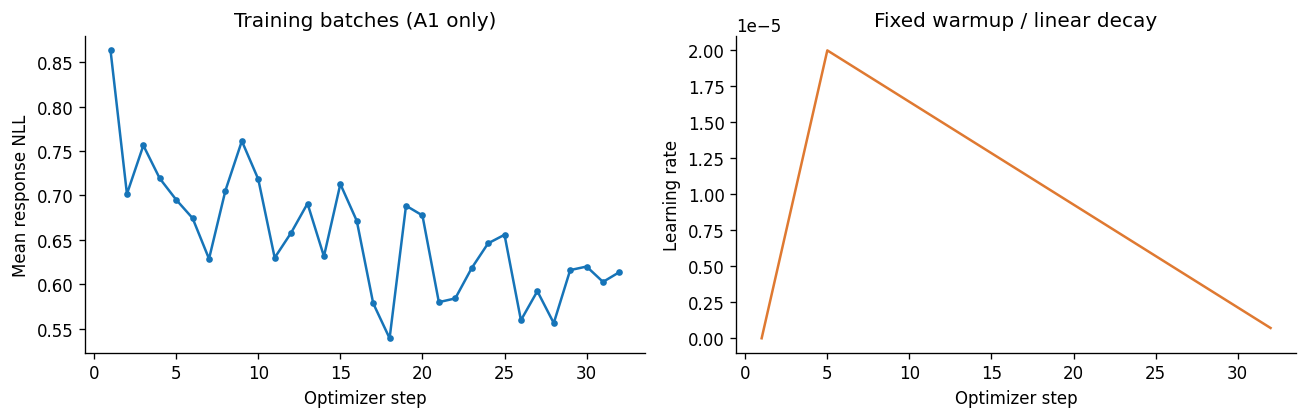

训练 step 记录的耗时合计 97.3 秒；不含模型加载、checkpoint I/O 和评分。


In [4]:
assert training['step'].tolist()==list(range(1,completed['global_step']+1))
assert np.isfinite(training[['loss','lr']].to_numpy()).all()
assert int(training['response_tokens'].sum())==completed['seen_response_tokens']
fig,axes = plt.subplots(1,2,figsize=(11,3.6))
axes[0].plot(training['step'],training['loss'],marker='.',color='#1674B8')
axes[0].set(xlabel='Optimizer step',ylabel='Mean response NLL',title='Training batches (A1 only)')
axes[1].plot(training['step'],training['lr'],color='#DF7931')
axes[1].set(xlabel='Optimizer step',ylabel='Learning rate',title='Fixed warmup / linear decay')
fig.tight_layout();plt.show();plt.close(fig)
print(f"训练 step 记录的耗时合计 {training['seconds'].sum():.1f} 秒；不含模型加载、checkpoint I/O 和评分。")

每一步的 batch 内容不同，因此训练曲线不等于固定评估集上的学习曲线。下面仅比较 A2 与 Dolly 的相同样本在两个模型下的 loss。

,条数,ref_NLL,SFT_NLL,平均下降量,loss 下降样本比例
split,,,,,
A2,512,0.8093,0.6374,0.1719,0.9746
C,512,2.2960,2.1643,0.1317,0.9121


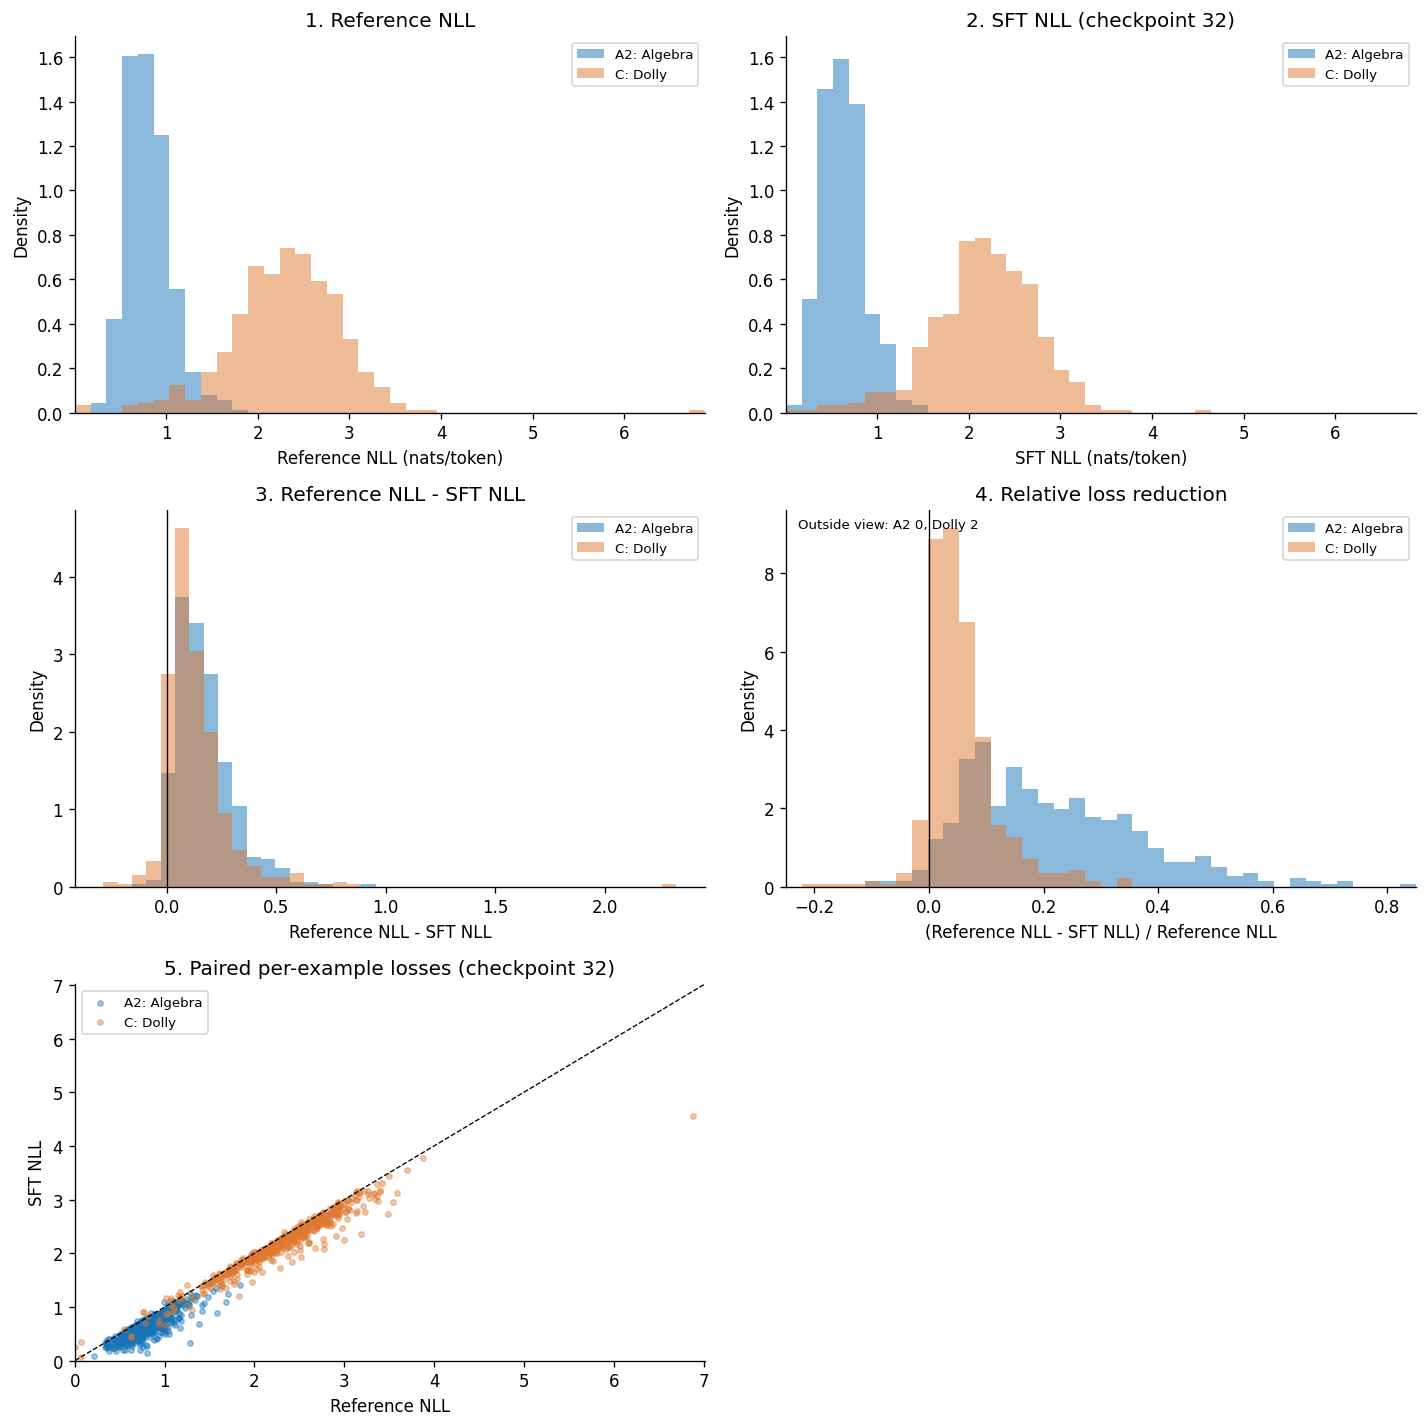

相对下降比例主图显示 [-0.25, 0.85]，均匀分为 40 桶；密度按每域全部样本归一化。
范围外样本如下，仍全部参与 AUC、top-k 等统计计算：


,id,split,ref_mean_nll,sft_mean_nll,relative_gain,response_tokens
850,dolly:general_qa:4916,C,0.006336,0.263840,-40.638957,8
982,dolly:general_qa:882,C,0.064526,0.353819,-4.483339,4


In [5]:
loss_table = evaluation.groupby('split').agg(条数=('id','size'),ref_NLL=('ref_mean_nll','mean'),
    SFT_NLL=('sft_mean_nll','mean'),平均下降量=('delta_loss','mean'))
loss_table['loss 下降样本比例'] = evaluation.groupby('split')['delta_loss'].apply(lambda x:(x>0).mean())
display(loss_table.round(4))
colors = {'A':'#1674B8','C':'#DF7931'}
domain_names = {'A':'A2: Algebra','C':'C: Dolly'}
scoring_steps = evaluation['checkpoint_step'].unique()
assert len(scoring_steps)==1
sft_step = int(scoring_steps[0]);assert sft_step==completed['global_step']
fig = plt.figure(figsize=(12,12))
grid = fig.add_gridspec(3,2)
axes = [fig.add_subplot(grid[row,col]) for row in range(2) for col in range(2)]
axes.append(fig.add_subplot(grid[2,0]))
nll_bins = np.histogram_bin_edges(evaluation[['ref_mean_nll','sft_mean_nll']].to_numpy().ravel(),bins=40)
relative_limits = (-0.25,0.85)
relative_bins = np.linspace(*relative_limits,41)
relative_outliers = evaluation.loc[~evaluation['relative_gain'].between(*relative_limits)]
distributions = [
    ('ref_mean_nll','Reference NLL (nats/token)','1. Reference NLL'),
    ('sft_mean_nll','SFT NLL (nats/token)',f'2. SFT NLL (checkpoint {sft_step})'),
    ('delta_loss','Reference NLL - SFT NLL','3. Reference NLL - SFT NLL'),
    ('relative_gain','(Reference NLL - SFT NLL) / Reference NLL','4. Relative loss reduction'),
]
for ax,(column,xlabel,title) in zip(axes[:4],distributions):
    bins = (relative_bins if column=='relative_gain' else nll_bins if column in {'ref_mean_nll','sft_mean_nll'}
            else np.histogram_bin_edges(evaluation[column],bins=40))
    for domain,group in evaluation.groupby('domain'):
        if column=='relative_gain':
            # Normalize by all domain samples, including those outside the view.
            weights = np.full(len(group),1/(len(group)*(bins[1]-bins[0])))
            ax.hist(group[column],bins=bins,weights=weights,alpha=.5,label=domain_names[domain],color=colors[domain])
        else:
            ax.hist(group[column],bins=bins,density=True,alpha=.5,label=domain_names[domain],color=colors[domain])
    if column in {'delta_loss','relative_gain'}: ax.axvline(0,color='black',linewidth=.8)
    ax.set(xlabel=xlabel,ylabel='Density',title=title)
    if column=='relative_gain':
        ax.set_xlim(*relative_limits)
        counts = relative_outliers['domain'].value_counts()
        ax.text(.02,.98,f"Outside view: A2 {counts.get('A',0)}, Dolly {counts.get('C',0)}",
                transform=ax.transAxes,ha='left',va='top',fontsize=8)
nll_ymax = max(ax.get_ylim()[1] for ax in axes[:2])
for ax in axes[:2]: ax.set(xlim=(nll_bins[0],nll_bins[-1]),ylim=(0,nll_ymax))
for domain,group in evaluation.groupby('domain'):
    axes[4].scatter(group['ref_mean_nll'],group['sft_mean_nll'],s=10,alpha=.4,label=domain_names[domain],color=colors[domain])
bound = evaluation[['ref_mean_nll','sft_mean_nll']].to_numpy().max()*1.02
axes[4].plot([0,bound],[0,bound],'k--',linewidth=.8)
axes[4].set(xlabel='Reference NLL',ylabel='SFT NLL',title=f'5. Paired per-example losses (checkpoint {sft_step})',
            xlim=(0,bound),ylim=(0,bound))
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)
print('相对下降比例主图显示 [-0.25, 0.85]，均匀分为 40 桶；密度按每域全部样本归一化。')
print('范围外样本如下，仍全部参与 AUC、top-k 等统计计算：')
display(relative_outliers[['id','split','ref_mean_nll','sft_mean_nll','relative_gain','response_tokens']].round(6))

## 4. 能否把 A2 排在 Dolly 前面？

In [6]:
score_keys = ['delta_loss','relative_gain','neg_ref_loss','neg_sft_loss']
score_labels = {'delta_loss':'loss 下降量','relative_gain':'相对下降比例',
                'neg_ref_loss':'ref loss，低值优先','neg_sft_loss':'SFT loss，低值优先'}
def point_metrics(frame,key,ties):
    y = (frame['domain']=='A').to_numpy(dtype=int)
    order = np.lexsort((ties,-frame[key].to_numpy()))
    return {'roc_auc':roc_auc_score(y,frame[key]),
            'precision_top_10pct':y[order[:math.ceil(len(y)*.1)]].mean(),
            'precision_top_20pct':y[order[:math.ceil(len(y)*.2)]].mean()}
for frame,stored in [(evaluation,metrics['main']),(matched,metrics['length_matched'])]:
    ties = np.random.default_rng(stored['tie_seed']).random(len(frame))
    for key in stored['scores']:
        for name,value in point_metrics(frame,key,ties).items():
            np.testing.assert_allclose(value,stored['scores'][key][name],rtol=0,atol=1e-12)
def interval(v): return f'[{v[0]:.4f}, {v[1]:.4f}]'
def metric_table(result,keys=score_keys):
    return pd.DataFrame([{'排序指标':score_labels.get(key,key),'ROC-AUC':round(result['scores'][key]['roc_auc'],4),
        'Top 10% A2':f"{result['scores'][key]['precision_top_10pct']:.1%}",
        'Top 20% A2':f"{result['scores'][key]['precision_top_20pct']:.1%}"} for key in keys]).set_index('排序指标')
display(metric_table(metrics['main']))
print('原始池和长度匹配池的 AUC、top-k 点估计均已重新计算，并与快照一致。')
print(f"原始池 top 10% 取前 {math.ceil(len(evaluation)*.1)} 条；A2/C 各占一半，随机 A2 占比期望为 50%。")

,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
loss 下降量,0.6162,60.2%,62.4%
相对下降比例,0.8563,98.1%,94.6%
ref loss，低值优先,0.9798,96.1%,97.1%
SFT loss，低值优先,0.9846,97.1%,97.6%


原始池和长度匹配池的 AUC、top-k 点估计均已重新计算，并与快照一致。
原始池 top 10% 取前 103 条；A2/C 各占一半，随机 A2 占比期望为 50%。


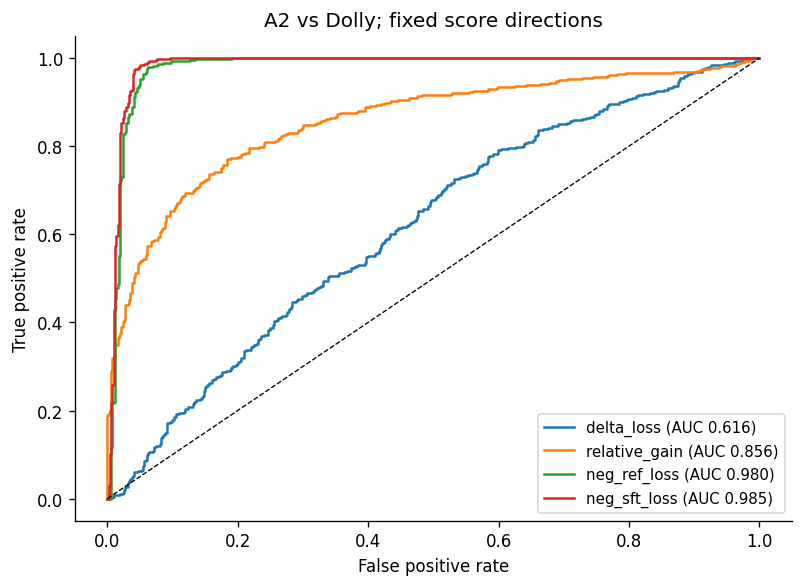

In [7]:
y = (evaluation['domain']=='A').to_numpy(dtype=int)
fig,ax = plt.subplots(figsize=(6.8,5))
for key in score_keys:
    fpr,tpr,_ = roc_curve(y,evaluation[key])
    ax.plot(fpr,tpr,label=f"{key} (AUC {metrics['main']['scores'][key]['roc_auc']:.3f})")
ax.plot([0,1],[0,1],'k--',linewidth=.8)
ax.set(xlabel='False positive rate',ylabel='True positive rate',title='A2 vs Dolly; fixed score directions')
ax.legend(fontsize=9);fig.tight_layout();plt.show();plt.close(fig)

## 5. 长度控制及相对基线的增益

仅用 A2/C 混合池的 prompt/response 长度四分位建立联合分桶，每桶从两域各取相同数量，
未使用模型分数挑样本。下面读取保存的匹配 ID，展示同一份控制样本。
匹配改变了评估人群，且分桶不能保证完全消除长度或其他混杂因素。

In [8]:
print(f'匹配保留 {len(matched)}/{len(evaluation)} 条（{len(matched)/len(evaluation):.1%}）。')
display(pd.DataFrame({'原始池':evaluation.groupby('split').size(),'长度匹配':matched.groupby('split').size()}))
display(metric_table(metrics['length_matched']))
length_rows = []
for pool,result in [('原始池',metrics['main']),('长度匹配',metrics['length_matched'])]:
    for column,values in result['length_baselines'].items():
        length_rows.append({'评估集':pool,'长度特征':column,'+长度 AUC':values['positive_auc'],'-长度 AUC':values['negative_auc']})
display(pd.DataFrame(length_rows).round(4))

匹配保留 156/1024 条（15.2%）。


,原始池,长度匹配
split,,
A2,512,78
C,512,78


,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
loss 下降量,0.7730,81.2%,81.2%
相对下降比例,0.9203,100.0%,96.9%
ref loss，低值优先,0.9297,81.2%,87.5%
SFT loss，低值优先,0.9466,87.5%,90.6%


,评估集,长度特征,+长度 AUC,-长度 AUC
0,原始池,prompt_tokens,0.9545,0.0455
1,原始池,response_tokens,0.5982,0.4018
2,长度匹配,prompt_tokens,0.5708,0.4292
3,长度匹配,response_tokens,0.5115,0.4885


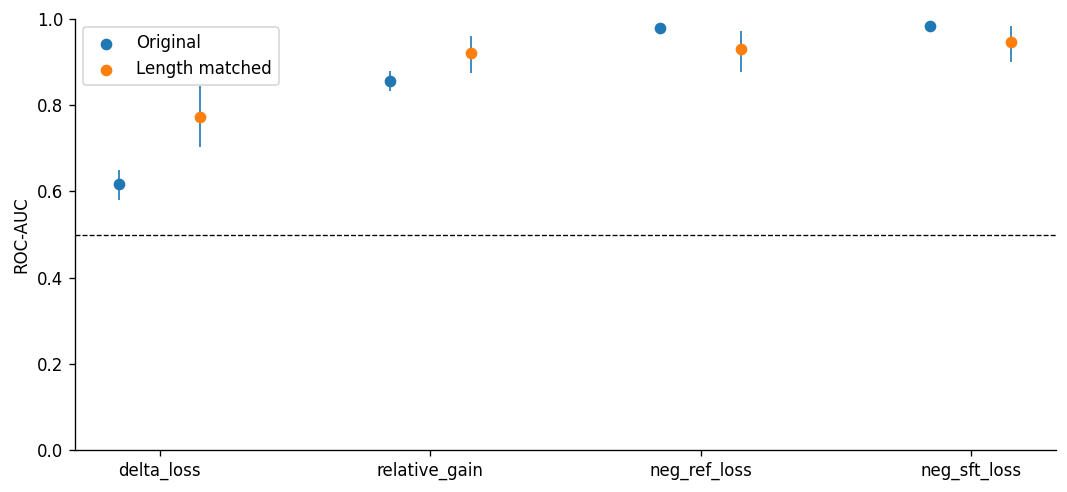

,评估集,比较,AUC 差,配对 95% CI,区间覆盖 0
0,原始池,delta_loss − neg_ref_loss,-0.3636,"[-0.4005, -0.3265]",False
1,原始池,delta_loss − neg_sft_loss,-0.3684,"[-0.4046, -0.3326]",False
2,长度匹配,delta_loss − neg_ref_loss,-0.1566,"[-0.2454, -0.0641]",False
3,长度匹配,delta_loss − neg_sft_loss,-0.1736,"[-0.2584, -0.0878]",False


In [9]:
fig,ax = plt.subplots(figsize=(9,4.2))
for shift,pool,result in [(-.15,'Original',metrics['main']),(.15,'Length matched',metrics['length_matched'])]:
    positions = np.arange(len(score_keys))+shift
    ax.scatter(positions,[result['scores'][k]['roc_auc'] for k in score_keys],label=pool,zorder=3)
    for position,key in zip(positions,score_keys): ax.vlines(position,*result['scores'][key]['roc_auc_ci95'],linewidth=1)
ax.axhline(.5,linestyle='--',color='black',linewidth=.8)
ax.set(xticks=np.arange(len(score_keys)),xticklabels=score_keys,ylabel='ROC-AUC',ylim=(0,1))
ax.legend();fig.tight_layout();plt.show();plt.close(fig)
comparisons = []
for pool,result in [('原始池',metrics['main']),('长度匹配',metrics['length_matched'])]:
    for baseline in ['neg_ref_loss','neg_sft_loss']:
        value = result['paired_delta_auc_minus_baseline'][baseline]
        lo,hi = value['ci95']
        comparisons.append({'评估集':pool,'比较':'delta_loss − '+baseline,'AUC 差':round(value['difference'],4),
                            '配对 95% CI':interval(value['ci95']),'区间覆盖 0':lo<=0<=hi})
display(pd.DataFrame(comparisons))

## 6. 结论与边界

In [10]:
texts = []
for key in ['delta_loss', 'relative_gain']:
    value = metrics['main']['scores'][key]
    lo, hi = value['roc_auc_ci95']
    signal = ('在固定方向上有区分信号' if lo > .5 else
              '区分方向与预设假设相反，没有事后翻转分数' if hi < .5 else
              '区间覆盖 0.5，尚无稳定的区分证据')
    texts.append(f"{score_labels[key]}：AUC {value['roc_auc']:.4f}，95% CI {interval(value['roc_auc_ci95'])}；{signal}。")
a2,c = metrics['loss_summary']['A2'],metrics['loss_summary']['C']
texts.append(f"A2 平均 NLL：{a2['ref_mean_nll']['mean']:.4f} → {a2['sft_mean_nll']['mean']:.4f}；"
                f"Dolly：{c['ref_mean_nll']['mean']:.4f} → {c['sft_mean_nll']['mean']:.4f}。")
if a2['delta_loss']['mean']>0 and c['delta_loss']['mean']>0:
    texts.append('两个域的平均 loss 都下降，区分效果没有依赖 Dolly 的平均 loss 恶化。')
for key in ['delta_loss', 'relative_gain']:
    v = metrics['length_matched']['scores'][key]
    texts.append(f"长度匹配后，{score_labels[key]} AUC 为 {v['roc_auc']:.4f}，95% CI {interval(v['roc_auc_ci95'])}。")
for label,result,baseline in [('loss 下降量在原始池中与 SFT loss 比较',metrics['main'],'neg_sft_loss'),
                             ('loss 下降量在长度匹配后与 ref loss 比较',metrics['length_matched'],'neg_ref_loss')]:
    v = result['paired_delta_auc_minus_baseline'][baseline]
    lo,hi = v['ci95']
    texts.append(f'{label}：配对区间覆盖 0，额外区分收益尚不确定。' if lo<=0<=hi else
                 f"{label}：AUC 差 {v['difference']:.4f}，95% CI {interval(v['ci95'])}。")
length_auc = metrics['length_matched']['length_baselines']['prompt_tokens']['positive_auc']
texts.append(f'长度匹配保留 {len(matched)/len(evaluation):.1%} 的样本；匹配后仅凭 prompt 长度的 AUC 仍为 {length_auc:.4f}，需注意桶内剩余差异。')
best = max(score_keys,key=lambda k:metrics['main']['scores'][k]['roc_auc'])
texts.append(f'本轮 {score_labels[best]} 的 AUC 点估计最高；这不自动证明它显著优于其他指标。')
display(Markdown('\n\n'.join(texts)))

loss 下降量：AUC 0.6162，95% CI [0.5810, 0.6498]；在固定方向上有区分信号。

相对下降比例：AUC 0.8563，95% CI [0.8324, 0.8795]；在固定方向上有区分信号。

A2 平均 NLL：0.8093 → 0.6374；Dolly：2.2960 → 2.1643。

两个域的平均 loss 都下降，区分效果没有依赖 Dolly 的平均 loss 恶化。

长度匹配后，loss 下降量 AUC 为 0.7730，95% CI [0.7025, 0.8443]。

长度匹配后，相对下降比例 AUC 为 0.9203，95% CI [0.8739, 0.9614]。

loss 下降量在原始池中与 SFT loss 比较：AUC 差 -0.3684，95% CI [-0.4046, -0.3326]。

loss 下降量在长度匹配后与 ref loss 比较：AUC 差 -0.1566，95% CI [-0.2454, -0.0641]。

长度匹配保留 15.2% 的样本；匹配后仅凭 prompt 长度的 AUC 仍为 0.5708，需注意桶内剩余差异。

本轮 SFT loss，低值优先 的 AUC 点估计最高；这不自动证明它显著优于其他指标。

本轮只有一个模型、一个训练 seed 和一次数据划分；bootstrap 区间不包含训练随机性。
平衡评估池上的 top-k 占比不能直接外推到其他 A2/C 比例的候选池。
Dolly 与 MATH 的来源、题型、格式和答案质量不同，可分性不能单独解释为领域效应。

后续可做（本轮未运行）：固定方案补独立 seed/划分，再在未参与选择的 A_test 上比较
按不同分数和随机方法选数后的实际训练收益，匹配训练 token 预算。

## 7. 验证记录与原始产物

In [11]:
display(pd.DataFrame([
    ('保存 optimizer / 自动恢复',f"{effective['save_optimizer']} / {effective['auto_resume']}"),
    ('A2 与原评分最大 NLL 差',metrics['a2_original_max_nll_difference']),
    ('相对下降分母保护触发数',metrics['relative_gain_denominator_clamps']),
    ('长度分桶数据',metrics['length_matching']['domains']),
    ('当前统计更新时间（UTC）',metrics['updated_at_utc']),
],columns=['检查','结果']))
print('原始 run：',manifest['source_run_dir'])
print('最终 checkpoint：',completed['checkpoint'])
print('时间来源：',manifest['timestamp_basis'])
display(pd.DataFrame([{'文件':name,'bytes':info['bytes'],'SHA-256':info['sha256']}
                     for name,info in manifest['files'].items()]).set_index('文件'))

,检查,结果
0,保存 optimizer / 自动恢复,True / True
1,A2 与原评分最大 NLL 差,"{'ref': 2.384185791015625e-05, 'sft': 3.039836883544922e-06}"
2,相对下降分母保护触发数,0
3,长度分桶数据,"[A, C]"
4,当前统计更新时间（UTC）,2026-10-22T10:44:49.444857+00:00


原始 run： /mnt/tianzhu_hot/data-picking/runs/math-algebra-numbertheory-dolly-lengthonly-qwen25-1p5b-seed42
最终 checkpoint： /mnt/tianzhu_hot/data-picking/runs/math-algebra-numbertheory-qwen25-1p5b-seed42/checkpoints/step-000032-1d6e5f24
时间来源： Original extension completion time; preserved when editing the review notebook


,bytes,SHA-256
文件,,
metrics.json,15315,29b72e87b478c8469bbc419872754174f41acfd48ac2b72b4a897b1229535fc0
per_example.parquet,293782,7bf29cdc0b747c3e3afc101a488cfab9d2432c2e73c8ce13dc041ca2b47a1d7b
length_matched_ids.json,3959,36abe16e340fd39054c01bf2f6ad003ed546a378fb885ef47518cc2a42b82ef1
effective_config.json,37891,77b1ac90935052496f3e256faf7581368cacc668a53731abcdaa5008d1326676
training_complete.json,275,e412bde65bca5db9f5d373fe911ffe428fa7fe92e1745536ea3210a6e50237bb
train.jsonl,5959,ed7d71c19a71272f636aa7f510f28718b9983d672a407ac1cef542803e9595e3
extension_config.json,1055,681c8a37bf05e0053acb238cc93294d64d1e6bcbef40969b71d66704075d5294
data_summary.json,4741,9a3daad2d7655792b7d79b74620fa7e941b73391500e3a45f5302ff861823fdd
duplicate_report.json,32040,4bb67cc9219a34c4ab614096b01097c09b5cb9dc9d5c89fa3201ad2fc1f9daed


评分使用完整 float32，因为 bf16 在不同 batch/padding 下曾出现约 0.0047 nats/token 的差异。
当前单样本评分与原 A2 批量推理采用相同 tokenization，并记录数值复核误差。
模型权重、optimizer、数据下载和 token 缓存保留在原始挂载；本目录保存便于 review 的分析快照。

## 附录：预先规定的反向原始 loss 基线

In [12]:
display(metric_table(metrics['main'],keys=['pos_ref_loss','pos_sft_loss']))

,ROC-AUC,Top 10% A2,Top 20% A2
排序指标,,,
pos_ref_loss,0.0202,0.0%,0.0%
pos_sft_loss,0.0154,0.0%,0.0%


## 8. 训练前后的逐样本梯度分析

下文是新增的探索性诊断，沿用上文同一批两域样本、reference 和 step 32 SFT 模型。
对每条样本的**回答正文平均 token NLL**计算 `g(x) = ∇θ L(x)`；完整 float32、eval 模式、SDPA math，
梯度不裁剪，没有 optimizer step，绑定参数只计一次。数据已经测量并保存，本节重跑仅需 CPU。

- 全局 norm：`||g||₂`；RMS 为 `||g||₂ / √参数量`。两模型参数量相同，二者的排序信息相同。
- 最大绝对梯度：`max |gᵢ|`，对应单个标量参数；逐参数张量统计另列。
- 层间分布：每层 RMS 和每层所占的梯度平方范数比例。
- 方向相似度：样本梯度与**同一模型上固定 128 条 A1 平均梯度**的 cosine。

norm 的前后差是两个 norm 的差，不能解释成两个梯度向量之差的 norm。
loss 下降量与相对下降比例仍按上文并列考察；本节不会用梯度诊断替换它们。

In [13]:
GRADIENT_DIRECTORY = '2026-10-22_093305Z_math-algebra-numbertheory-dolly-lengthonly-qwen25-1p5b-seed42'

import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import roc_auc_score
%matplotlib inline
GROOT = next((p for p in [Path.cwd(),Path.cwd()/'experiments-analysis'/GRADIENT_DIRECTORY]
              if (p/'snapshot/gradient_metrics.json').is_file()),None)
if GROOT is None: raise FileNotFoundError('请使用当前实验目录或仓库根目录作为工作目录。')
GMANIFEST = json.loads((GROOT/'manifest.json').read_text())
for name in ['gradient_metrics.json','gradient_per_example.parquet','gradient_per_layer.parquet',
             'gradient_parameter_summary.parquet','gradient_provenance.json']:
    raw = (GROOT/'snapshot'/name).read_bytes()
    assert hashlib.sha256(raw).hexdigest()==GMANIFEST['files'][name]['sha256'],name
gm = json.loads((GROOT/'snapshot/gradient_metrics.json').read_text())
gd = pd.read_parquet(GROOT/'snapshot/gradient_per_example.parquet')
gl = pd.read_parquet(GROOT/'snapshot/gradient_per_layer.parquet')
gp = pd.read_parquet(GROOT/'snapshot/gradient_parameter_summary.parquet')
gmatched = gd.set_index('id').loc[gm['length_matched_ids']].reset_index()
gdomains = gm['domains'];gnames = gm['domain_names']
gcolors = {'A':'#1674B8',gdomains[1]:'#DF7931'}
gshort = {d:('A2' if d=='A' else gnames[d].split(': ',1)[1]) for d in gdomains}
assert gd.id.is_unique and gd.groupby('domain').size().to_dict()=={d:512 for d in gdomains}
assert set(gl.id)==set(gd.id) and set(gp.domain)==set(gdomains)
assert gm['checkpoint_step']==32
assert max(gm['nll_difference_from_loss_notebook'].values())<=gm['nll_crosscheck_tolerance']
gfigures = []
print('梯度数据来源：',gm['measurement_run'])
print('全参数数量（绑定权重只计一次）：',f"{gm['parameter_count']:,}")
print('与上文 loss 最大数值复核差：',gm['nll_difference_from_loss_notebook'])
print('这些差异来自原有单样本/批量 FP32 计算路径；本节未改写上文的 loss 数据。')

梯度数据来源： /mnt/tianzhu_hot/data-picking/runs/math-algebra-numbertheory-dolly-lengthonly-qwen25-1p5b-seed42
全参数数量（绑定权重只计一次）： 1,543,714,304
与上文 loss 最大数值复核差： {'ref': 0.0, 'sft': 0.0}
这些差异来自原有单样本/批量 FP32 计算路径；本节未改写上文的 loss 数据。


### 8.1 全局梯度大小、最大值及前后变化

,数据,模型,样本数,norm 均值,norm 中位数,norm Q25,norm Q75,RMS 中位数,max|g| 中位数
0,A2: Algebra,ref,512,22.3597,19.1785,14.4551,26.5516,4.881e-04,1.8033
1,A2: Algebra,sft,512,13.2167,11.9302,9.7128,15.5442,3.036e-04,1.7030
2,C: Dolly,ref,512,32.0652,28.4837,21.7420,38.0915,7.250e-04,3.3630
3,C: Dolly,sft,512,25.0865,23.0822,18.6263,29.1612,5.875e-04,3.4302


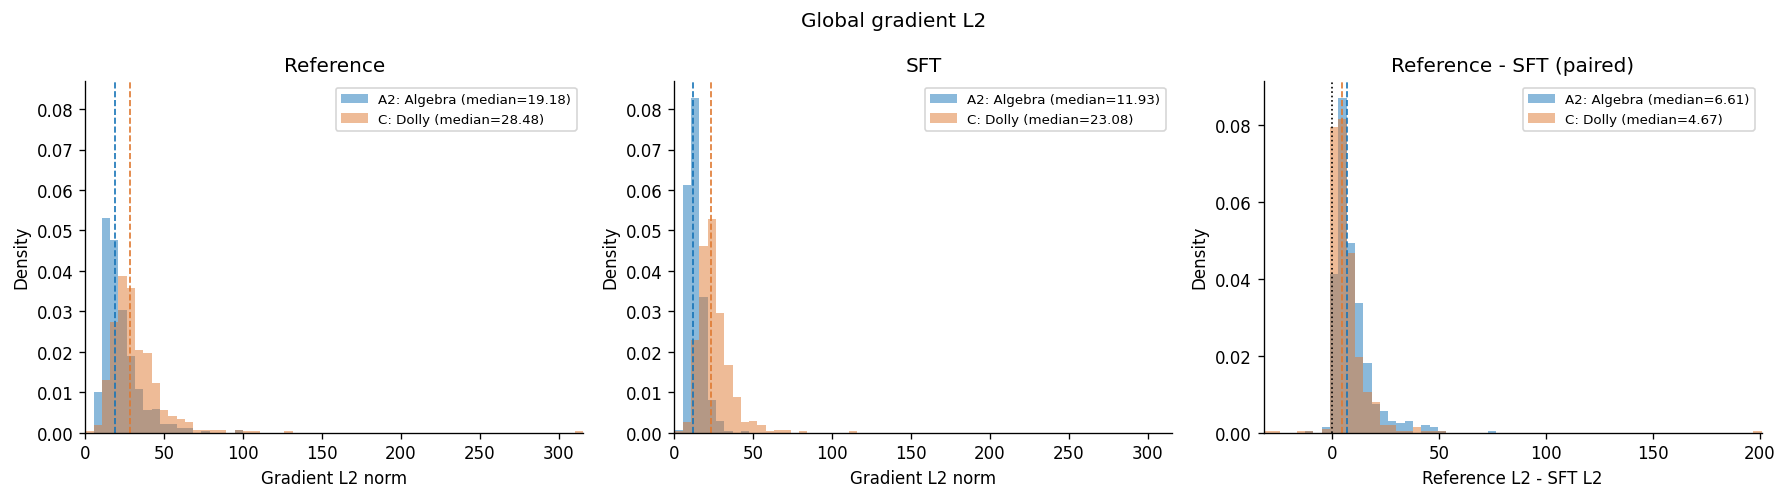

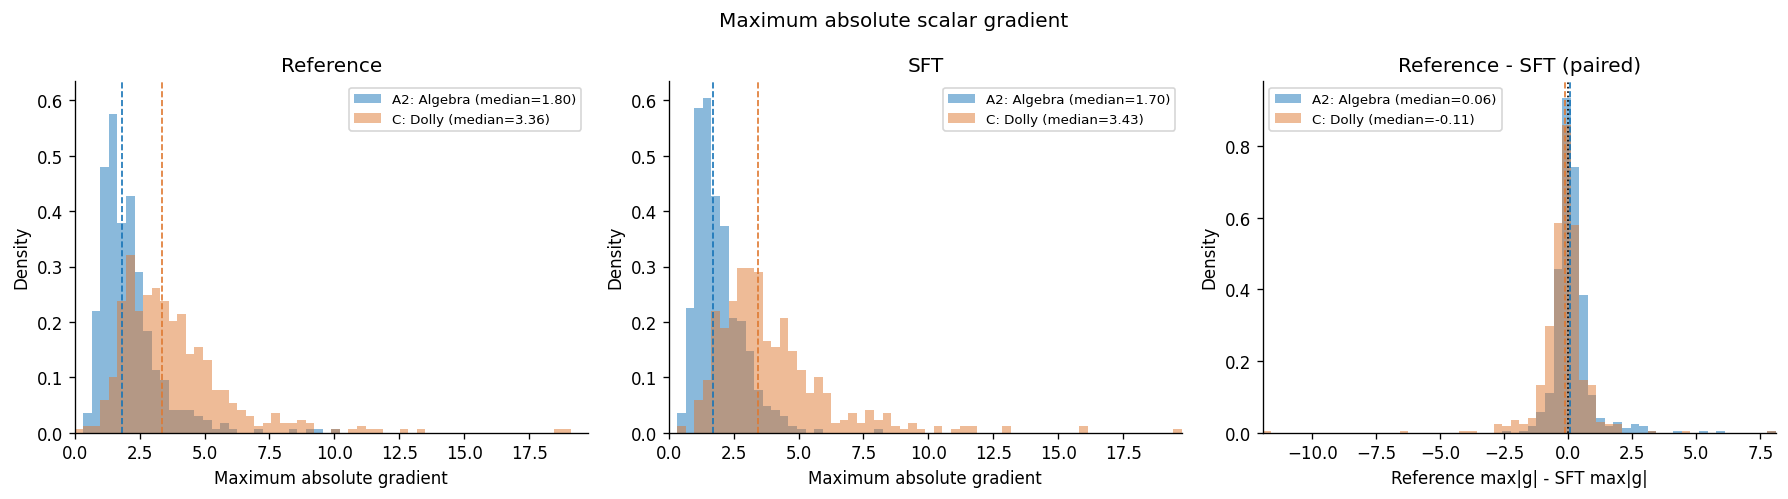

,指标,数据,ref 中位数,SFT 中位数,配对差值中位数,差值 > 0 比例
0,global gradient L2,A2: Algebra,19.1785,11.9302,6.6052,0.9863
1,global gradient L2,C: Dolly,28.4837,23.0822,4.6727,0.9844
2,maximum absolute gradient,A2: Algebra,1.8033,1.7030,0.0585,0.5781
3,maximum absolute gradient,C: Dolly,3.3630,3.4302,-0.1126,0.3848


**观测：**

A2: Algebra 的 global gradient L2：ref/SFT 中位数为 19.1785/11.9302；逐样本 ref−SFT 差值的中位数为 6.6052，98.6% 的样本差值为正。

C: Dolly 的 global gradient L2：ref/SFT 中位数为 28.4837/23.0822；逐样本 ref−SFT 差值的中位数为 4.6727，98.4% 的样本差值为正。

两域 global gradient L2 的中位数差（A2−Dolly）从 ref 的 -9.3052 变为 SFT 的 -11.1520；这是中位数的位置差，分布形状见图。

A2: Algebra 的 maximum absolute gradient：ref/SFT 中位数为 1.8033/1.7030；逐样本 ref−SFT 差值的中位数为 0.0585，57.8% 的样本差值为正。

C: Dolly 的 maximum absolute gradient：ref/SFT 中位数为 3.3630/3.4302；逐样本 ref−SFT 差值的中位数为 -0.1126，38.5% 的样本差值为正。

两域 maximum absolute gradient 的中位数差（A2−Dolly）从 ref 的 -1.5596 变为 SFT 的 -1.7272；这是中位数的位置差，分布形状见图。

In [14]:
grow = []
for domain,group in gd.groupby('domain'):
    for prefix in ['ref','sft']:
        norm = group[f'{prefix}_grad_l2']
        grow.append({'数据':gnames[domain],'模型':prefix,'样本数':len(group),
                     'norm 均值':norm.mean(),'norm 中位数':norm.median(),
                     'norm Q25':norm.quantile(.25),'norm Q75':norm.quantile(.75),
                     'RMS 中位数':group[f'{prefix}_grad_rms'].median(),
                     'max|g| 中位数':group[f'{prefix}_grad_max_abs'].median()})
# Plain DataFrame display works without pandas' optional Jinja2/Styler dependency.
gsummary = pd.DataFrame(grow)
gsummary_display = gsummary.copy()
for column,pattern in {'norm 均值':'{:.4f}','norm 中位数':'{:.4f}',
                      'norm Q25':'{:.4f}','norm Q75':'{:.4f}',
                      'RMS 中位数':'{:.3e}','max|g| 中位数':'{:.4f}'}.items():
    gsummary_display[column] = gsummary_display[column].map(pattern.format)
display(gsummary_display)
# Each metric gets three overlaid two-domain distributions, in the same order.
for key,title,xlabel in [('grad_l2','Global gradient L2','Gradient L2 norm'),
                         ('grad_max_abs','Maximum absolute scalar gradient','Maximum absolute gradient')]:
    value_bins = np.linspace(0,gd[[f'ref_{key}',f'sft_{key}']].to_numpy().max(),61)
    paired_difference = gd[f'ref_{key}']-gd[f'sft_{key}']
    difference_bins = np.histogram_bin_edges(paired_difference,bins=60)
    fig,axes = plt.subplots(1,3,figsize=(15,4.2))
    for ax,stage in zip(axes,['ref','sft','difference']):
        bins = difference_bins if stage=='difference' else value_bins
        for domain,group in gd.groupby('domain'):
            values = (group[f'ref_{key}']-group[f'sft_{key}'] if stage=='difference'
                      else group[f'{stage}_{key}'])
            median = values.median()
            assert np.histogram(values,bins=bins)[0].sum()==len(values)
            ax.hist(values,bins=bins,density=True,alpha=.5,color=gcolors[domain],
                    label=f'{gnames[domain]} (median={median:.2f})')
            ax.axvline(median,color=gcolors[domain],linestyle='--',linewidth=1)
        ax.set(xlim=(bins[0],bins[-1]),ylabel='Density')
        if stage=='difference':
            ax.axvline(0,color='black',linestyle=':',linewidth=1)
            difference_label = 'Reference L2 - SFT L2' if key=='grad_l2' else 'Reference max|g| - SFT max|g|'
            ax.set(title='Reference - SFT (paired)',xlabel=difference_label)
        else:
            ax.set(title='Reference' if stage=='ref' else 'SFT',xlabel=xlabel)
        ax.legend(fontsize=8)
    value_ymax = max(ax.get_ylim()[1] for ax in axes[:2])
    for ax in axes[:2]: ax.set_ylim(0,value_ymax)
    fig.suptitle(title,fontsize=12)
    fig.tight_layout();plt.show();plt.close(fig)
gchanges=[];gnotes=[]
for key,label in [('grad_l2','global gradient L2'),('grad_max_abs','maximum absolute gradient')]:
    for domain,group in gd.groupby('domain'):
        before,after = group[f'ref_{key}'],group[f'sft_{key}']
        difference = before-after
        fraction = (difference>0).mean()
        gchanges.append({'指标':label,'数据':gnames[domain],'ref 中位数':before.median(),
                         'SFT 中位数':after.median(),'配对差值中位数':difference.median(),'差值 > 0 比例':fraction})
        gnotes.append(f"{gnames[domain]} 的 {label}：ref/SFT 中位数为 {before.median():.4f}/{after.median():.4f}；"
                      f"逐样本 ref−SFT 差值的中位数为 {difference.median():.4f}，{fraction:.1%} 的样本差值为正。")
    target_group,other_group = gd.loc[gd.domain=='A'],gd.loc[gd.domain==gdomains[1]]
    ref_gap = target_group[f'ref_{key}'].median()-other_group[f'ref_{key}'].median()
    sft_gap = target_group[f'sft_{key}'].median()-other_group[f'sft_{key}'].median()
    gnotes.append(f"两域 {label} 的中位数差（A2−{gshort[gdomains[1]]}）从 ref 的 {ref_gap:.4f} 变为 SFT 的 {sft_gap:.4f}；这是中位数的位置差，分布形状见图。")
display(pd.DataFrame(gchanges).round(4))
display(Markdown('**观测：**\n\n'+'\n\n'.join(gnotes)))

每项指标依次展示 ref、SFT、逐样本 ref−SFT 的两域叠加分布，共六张分布图。
直方图使用全部样本、线性坐标和每域归一化的密度；同一指标的 ref/SFT 共用分桶、横轴范围和纵轴尺度，
两域在差值图中也共用分桶。彩色虚线表示各域中位数，差值图的黑色点线表示零。
正差值表示 SFT 后该指标下降；负差值表示上升。
本节展示原始评估池，长度匹配对照见 8.4。

差值先按同一条样本计算，再画分布：global gradient 使用 `||g_ref||₂ − ||g_sft||₂`，
maximum 使用 `max|g_ref| − max|g_sft|`，不是先相减梯度向量再求 norm/maximum。
norm、最大单参数梯度和 loss 描述不同的量，它们不必同步变化。

### 8.2 哪些层和参数承担了梯度？

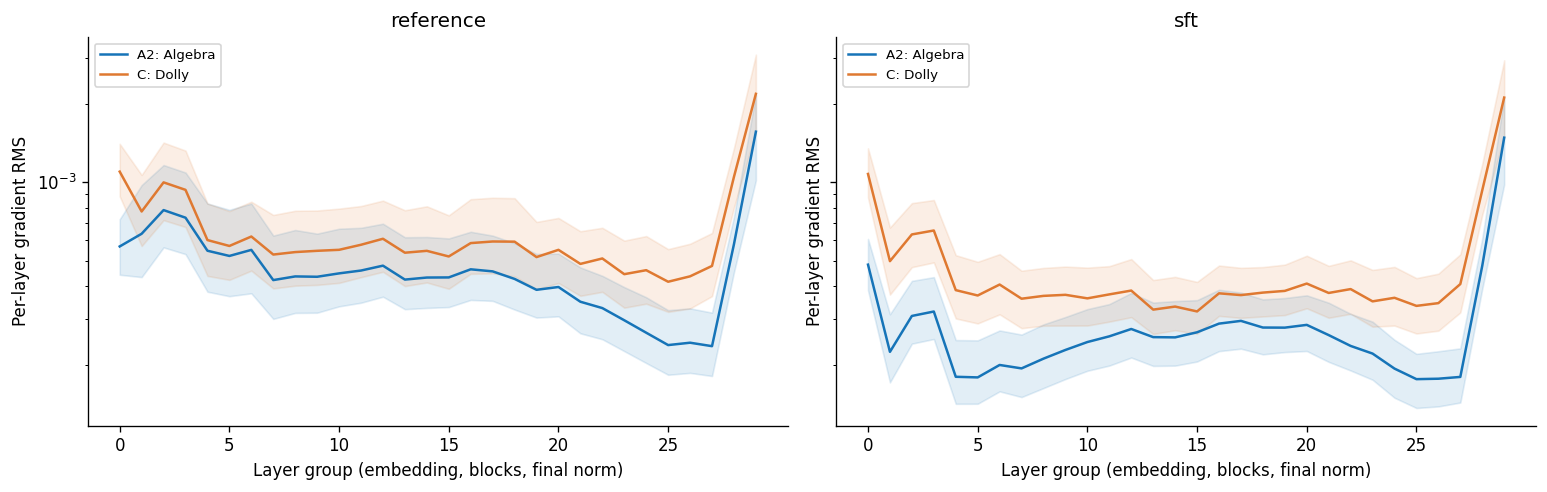

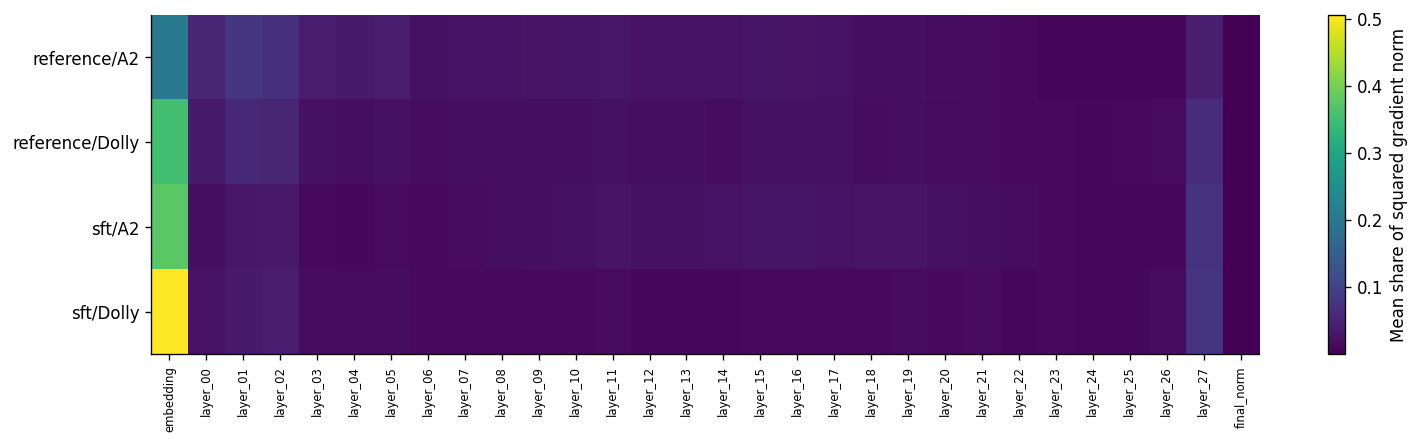

,domain,model,parameter,numel,max_abs_winner_count,max_abs_winner_fraction,grad_l2_median,grad_rms_median,grad_max_abs_median
0,A,reference,model.embed_tokens.weight,233373696,463,0.904297,8.686544,0.000569,1.772312
1,A,reference,model.layers.5.mlp.up_proj.weight,13762560,49,0.095703,2.164476,0.000583,0.567771
2,A,sft,model.embed_tokens.weight,233373696,512,1.000000,7.400305,0.000484,1.702993
3,C,reference,model.embed_tokens.weight,233373696,510,0.996094,16.786752,0.001099,3.362964
4,C,reference,model.layers.26.mlp.down_proj.weight,13762560,1,0.001953,1.917898,0.000517,0.168497
5,C,reference,model.layers.12.self_attn.k_proj.weight,393216,1,0.001953,0.774847,0.001236,0.181166
6,C,sft,model.embed_tokens.weight,233373696,512,1.000000,16.445337,0.001077,3.430197


**观测：**

A2: Algebra：平方 norm 占比最大的组为 ref 的 `embedding`（20.4%）和 SFT 的 `embedding`（37.6%）。

C: Dolly：平方 norm 占比最大的组为 ref 的 `embedding`（35.2%）和 SFT 的 `embedding`（50.6%）。

In [15]:
gnorms = pd.concat([gd[['id','ref_grad_l2']].rename(columns={'ref_grad_l2':'global_norm'}).assign(model='reference'),
                   gd[['id','sft_grad_l2']].rename(columns={'sft_grad_l2':'global_norm'}).assign(model='sft')],ignore_index=True)
gle = gl.merge(gnorms,on=['id','model'],validate='many_to_one')
gle['energy_share'] = gle.grad_l2**2/gle.global_norm**2
np.testing.assert_allclose(gle.groupby(['id','model']).energy_share.sum(),1,rtol=1e-6,atol=1e-6)
gorder = ['embedding']+sorted(k for k in gl.layer.unique() if k.startswith('layer_'))
gorder += sorted(k for k in gl.layer.unique() if k not in gorder)
fig,axes = plt.subplots(1,2,figsize=(13,4.2),sharey=True)
for ax,model in zip(axes,['reference','sft']):
    for domain in gdomains:
        group = gl.loc[(gl.model==model)&(gl.domain==domain)].groupby('layer').grad_rms
        ax.plot(range(len(gorder)),group.median().reindex(gorder),label=gnames[domain],color=gcolors[domain])
        ax.fill_between(range(len(gorder)),group.quantile(.25).reindex(gorder),group.quantile(.75).reindex(gorder),color=gcolors[domain],alpha=.12)
    ax.set(yscale='log',xlabel='Layer group (embedding, blocks, final norm)',ylabel='Per-layer gradient RMS',title=model)
    ax.set_xticks(range(0,len(gorder),5));ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)
gshares = gle.groupby(['model','domain','layer']).energy_share.mean().unstack('layer').reindex(columns=gorder)
fig,ax = plt.subplots(figsize=(13,3.8))
heat = ax.imshow(gshares.to_numpy(),aspect='auto',cmap='viridis')
ax.set_yticks(range(len(gshares)));ax.set_yticklabels([f'{m}/{gshort[d]}' for m,d in gshares.index])
ax.set_xticks(range(len(gorder)));ax.set_xticklabels(gorder,rotation=90,fontsize=7)
fig.colorbar(heat,ax=ax,label='Mean share of squared gradient norm')
fig.tight_layout();plt.show();plt.close(fig)
top=[]
for domain,group in gd.groupby('domain'):
    for prefix,model in [('ref','reference'),('sft','sft')]:
        for parameter,count in group[f'{prefix}_grad_max_abs_parameter'].value_counts().head(3).items():
            top.append({'domain':domain,'model':model,'parameter':parameter,'max_abs_winner_count':int(count),
                        'max_abs_winner_fraction':count/len(group)})
gtop = pd.DataFrame(top).merge(gp,on=['domain','model','parameter'],validate='many_to_one')
display(gtop[['domain','model','parameter','numel','max_abs_winner_count','max_abs_winner_fraction',
              'grad_l2_median','grad_rms_median','grad_max_abs_median']].round(6))
layer_notes=[]
for domain in gdomains:
    ref_share,sft_share = gshares.loc[('reference',domain)],gshares.loc[('sft',domain)]
    layer_notes.append(f"{gnames[domain]}：平方 norm 占比最大的组为 ref 的 `{ref_share.idxmax()}`（{ref_share.max():.1%}）"
                       f"和 SFT 的 `{sft_share.idxmax()}`（{sft_share.max():.1%}）。")
display(Markdown('**观测：**\n\n'+'\n\n'.join(layer_notes)))

曲线阴影为样本间 Q25–Q75。RMS 按层参数量归一化；热图先按每条样本的全局平方 norm 归一化，
再跨样本取均值。二者分别反映每个参数的尺度和层的总贡献，不能互相替代。
`embedding` 包含绑定的输入 embedding / 输出 lm-head 合并梯度，权重只计一次。

表中列出每组最常出现全局最大单参数梯度的三个参数张量，次数和占比以该域的全部 512 条为分母。
`grad_max_abs_median` 是这个张量逐样本最大绝对梯度的中位数。
完整逐参数聚合表保存在 `gradient_parameter_summary.parquet`，逐样本逐参数明细仍在原始测量目录。

### 8.3 梯度方向与 A1 平均梯度的相似度

,模型,A1 条数,A1 平均梯度 norm,A1 平均 NLL,embedding/head 绑定
0,reference,128,9.830080,0.821362,True
1,sft,128,1.261531,0.515407,True


,数据,模型,cosine 均值,cosine 中位数,Q25,Q75,cosine > 0 比例
0,A2: Algebra,ref,0.42029,0.42710,0.31691,0.54781,1.00000
1,A2: Algebra,sft,0.02147,0.02208,-0.00748,0.05077,0.69727
2,C: Dolly,ref,0.14062,0.13375,0.09231,0.17956,0.99023
3,C: Dolly,sft,-0.00462,-0.00445,-0.01953,0.01119,0.44531


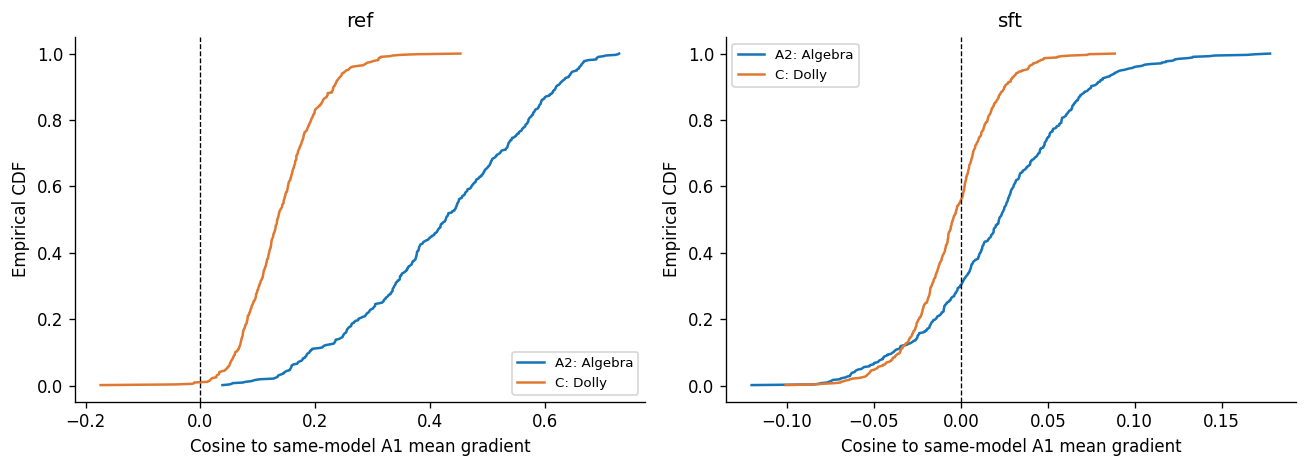

In [16]:
display(pd.DataFrame([{'模型':k,'A1 条数':len(v['ids']),'A1 平均梯度 norm':v['norm'],
                      'A1 平均 NLL':v['mean_nll'],'embedding/head 绑定':v['tied_input_output_embeddings']}
                     for k,v in gm['anchor_summary'].items()]).round(6))
cosine_rows=[]
for domain,group in gd.groupby('domain'):
    for prefix in ['ref','sft']:
        values = group[f'{prefix}_cos_to_a1']
        cosine_rows.append({'数据':gnames[domain],'模型':prefix,'cosine 均值':values.mean(),
                            'cosine 中位数':values.median(),'Q25':values.quantile(.25),'Q75':values.quantile(.75),
                            'cosine > 0 比例':(values>0).mean()})
display(pd.DataFrame(cosine_rows).round(5))
fig,axes = plt.subplots(1,2,figsize=(11,4))
for ax,prefix in zip(axes,['ref','sft']):
    for domain,group in gd.groupby('domain'):
        values = np.sort(group[f'{prefix}_cos_to_a1'])
        ax.plot(values,np.arange(1,len(values)+1)/len(values),label=gnames[domain],color=gcolors[domain])
    ax.axvline(0,color='black',linestyle='--',linewidth=.8)
    ax.set(title=prefix,xlabel='Cosine to same-model A1 mean gradient',ylabel='Empirical CDF')
    ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)

两模型使用同一批 128 条 A1，但平均梯度分别在各自参数位置计算，所以参照向量会改变。
这里的两个 cosine 不是 `cos(g_ref(x), g_sft(x))`，也不是相对同一个固定向量的前后夹角变化。

在单步、足够小的普通梯度下降近似下，正向对齐意味着沿样本的负梯度更新可能降低该 A1 子集的平均 loss。
实际 AdamW 更新还受预条件、动量和有限步长影响；而 A1 是训练数据，因此这个参照也不能替代未见目标域上的训练收益验证。

### 8.4 与 loss、长度的关系及区分信息

,domain,model,"rho(norm,NLL)","rho(norm,prompt length)","rho(norm,response length)"
0,A,ref,0.4248,-0.3656,-0.8736
1,A,sft,0.4084,-0.1723,-0.7054
2,C,ref,0.1798,-0.1700,-0.9266
3,C,sft,0.0922,-0.1190,-0.9383


,domain,"rho(norm drop,loss decrease)","rho(norm drop,relative decrease)"
0,A,0.8190,0.7634
1,C,0.7467,0.7630


以上均为域内 Spearman 相关；loss 下降量与相对下降比例分别报告。
长度匹配沿用上文样本： {'A': 78, 'C': 78}


,raw AUC,raw 95% CI,length_matched AUC,length_matched 95% CI
梯度特征,,,,
ref_grad_l2,0.2760,"[0.2455, 0.3089]",0.4019,"[0.3152, 0.4887]"
sft_grad_l2,0.1056,"[0.0872, 0.1263]",0.1399,"[0.0840, 0.1987]"
grad_l2_delta,0.6025,"[0.5680, 0.6391]",0.6905,"[0.6035, 0.7683]"
ref_grad_max_abs,0.1911,"[0.1655, 0.2194]",0.2567,"[0.1841, 0.3353]"
sft_grad_max_abs,0.1433,"[0.1224, 0.1675]",0.1867,"[0.1203, 0.2558]"
grad_max_abs_delta,0.6282,"[0.5916, 0.6627]",0.6164,"[0.5301, 0.7048]"
ref_cos_to_a1,0.9443,"[0.9299, 0.9581]",0.9660,"[0.9398, 0.9875]"
sft_cos_to_a1,0.6995,"[0.6677, 0.7340]",0.6177,"[0.5245, 0.7055]"


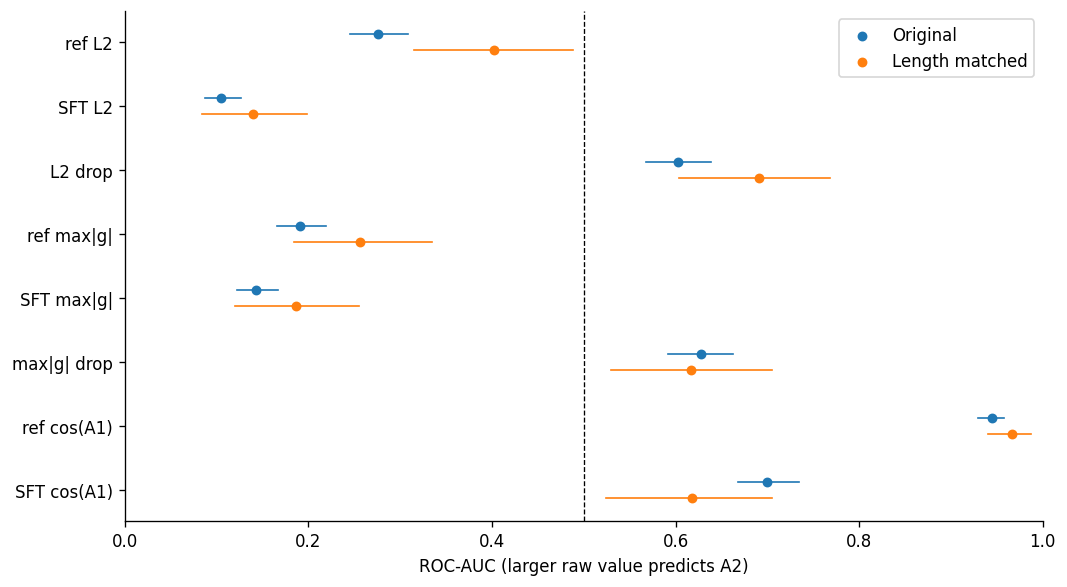

In [17]:
display(pd.DataFrame(gm['norm_correlations']).rename(columns={'nll':'rho(norm,NLL)',
    'prompt_tokens':'rho(norm,prompt length)','response_tokens':'rho(norm,response length)'}).round(4))
display(pd.DataFrame(gm['norm_drop_loss_correlations']).rename(columns={
    'delta_loss':'rho(norm drop,loss decrease)','relative_gain':'rho(norm drop,relative decrease)'}).round(4))
print('以上均为域内 Spearman 相关；loss 下降量与相对下降比例分别报告。')
print('长度匹配沿用上文样本：',gm['length_matched_counts'])
gkeys = ['ref_grad_l2','sft_grad_l2','grad_l2_delta','ref_grad_max_abs','sft_grad_max_abs',
         'grad_max_abs_delta','ref_cos_to_a1','sft_cos_to_a1']
glabels = ['ref L2','SFT L2','L2 drop','ref max|g|','SFT max|g|','max|g| drop','ref cos(A1)','SFT cos(A1)']
def ginterval(v): return f'[{v[0]:.4f}, {v[1]:.4f}]'
auc_rows=[]
for key in gkeys:
    row={'梯度特征':key}
    for pool,frame in [('raw',gd),('length_matched',gmatched)]:
        saved = gm['comparisons'][pool]['gradient_scores'][key]
        np.testing.assert_allclose(roc_auc_score(frame.domain=='A',frame[key]),saved['roc_auc'],rtol=0,atol=1e-12)
        row[f'{pool} AUC'] = round(saved['roc_auc'],4)
        row[f'{pool} 95% CI'] = ginterval(saved['roc_auc_ci95'])
    auc_rows.append(row)
display(pd.DataFrame(auc_rows).set_index('梯度特征'))
fig,ax = plt.subplots(figsize=(9,5))
for shift,pool,label in [(-.12,'raw','Original'),(.12,'length_matched','Length matched')]:
    for i,key in enumerate(gkeys):
        value = gm['comparisons'][pool]['gradient_scores'][key]
        lo,hi = value['roc_auc_ci95'];point = value['roc_auc']
        ax.plot([lo,hi],[i+shift,i+shift],color=('C0' if pool=='raw' else 'C1'),linewidth=1)
        ax.scatter(point,i+shift,color=('C0' if pool=='raw' else 'C1'),label=label if i==0 else None,s=24)
ax.axvline(.5,color='black',linestyle='--',linewidth=.8)
ax.set(xlim=(0,1),yticks=range(len(gkeys)),yticklabels=glabels,xlabel='ROC-AUC (larger raw value predicts A2)')
ax.invert_yaxis();ax.legend();fig.tight_layout();plt.show();plt.close(fig)

A2 固定为正类，所有梯度特征采用“数值越大越倾向 A2”，没有看到结果后翻转方向。
AUC 小于 0.5 表示较大值更倾向另一组，并不等于没有区分信息。
区间来自按域分层、按问题组抽样的 2,000 次 bootstrap；这些多指标结果属于探索性诊断。
长度对照沿用本 notebook 上文的匹配 ID，并未重新挑选适合梯度的样本。

### 8.5 本轮观察与解释边界

In [18]:
observations=[]
for domain,group in gd.groupby('domain'):
    loss_drop = group.delta_loss.mean()
    norm_drop = (1-group.sft_grad_l2/group.ref_grad_l2).median()
    observations.append(f"{gnames[domain]}：平均 loss 变化量（ref−SFT）为 {loss_drop:.4f}，"
                         f"配对 norm 相对下降的中位数为 {norm_drop:.1%}。")
    if loss_drop<0 and norm_drop>0:
        observations.append(f"{gnames[domain]} 的平均 loss 上升，但 norm 的配对中位变化仍为下降；梯度变小与 loss 改善并非等价。")
for key,label in [('ref_grad_l2','训练前 norm'),('sft_grad_l2','训练后 norm'),
                  ('ref_cos_to_a1','训练前 A1 cosine'),('sft_cos_to_a1','训练后 A1 cosine')]:
    graw_result = gm['comparisons']['raw']['gradient_scores'][key]
    gmatched_result = gm['comparisons']['length_matched']['gradient_scores'][key]
    low,high = gmatched_result['roc_auc_ci95']
    direction = ('在该匹配子集中，较大值倾向 A2' if low>.5 else
                 f'在该匹配子集中，较大值倾向 {gnames[gdomains[1]]}' if high<.5 else
                 '该匹配子集的区间覆盖 0.5，尚无稳定的区分证据')
    observations.append(f"{label}：原始 AUC {graw_result['roc_auc']:.4f}；长度匹配 AUC {gmatched_result['roc_auc']:.4f} "
                         f"（95% CI {ginterval(gmatched_result['roc_auc_ci95'])}）；{direction}。")
    raw_low,raw_high = graw_result['roc_auc_ci95']
    if key=='ref_grad_l2' and (raw_low>.5 or raw_high<.5) and low<=.5<=high:
        observations.append('训练前 norm 在原始池中的区分信号未在长度对照中稳定保留。匹配也改变了评估人群，不能把差异全部归因于长度。')
display(Markdown('**观测结果：**\n\n'+'\n\n'.join(observations)))

**观测结果：**

A2: Algebra：平均 loss 变化量（ref−SFT）为 0.1719，配对 norm 相对下降的中位数为 35.1%。

C: Dolly：平均 loss 变化量（ref−SFT）为 0.1317，配对 norm 相对下降的中位数为 16.9%。

训练前 norm：原始 AUC 0.2760；长度匹配 AUC 0.4019 （95% CI [0.3152, 0.4887]）；在该匹配子集中，较大值倾向 C: Dolly。

训练后 norm：原始 AUC 0.1056；长度匹配 AUC 0.1399 （95% CI [0.0840, 0.1987]）；在该匹配子集中，较大值倾向 C: Dolly。

训练前 A1 cosine：原始 AUC 0.9443；长度匹配 AUC 0.9660 （95% CI [0.9398, 0.9875]）；在该匹配子集中，较大值倾向 A2。

训练后 A1 cosine：原始 AUC 0.6995；长度匹配 AUC 0.6177 （95% CI [0.5245, 0.7055]）；在该匹配子集中，较大值倾向 A2。

**解释边界：** norm 衡量局部梯度大小，cosine 描述相对指定 A1 参照的方向；单独任何一个都不能当作
“继续训练这个样本的收益”。层间占比、回答长度、loss 尺度和来源/格式差异需要一起看。
尤其要区分原始池与长度匹配子集的结论，匹配后的区间不包含训练 seed 的不确定性。
要验证选数效用，仍需固定预算进行实际选数训练，并在未参与选择的目标域测试集上评估。